# QED-C Benchmarks - Modularized
This notebook shows the three-part modularized benchmark flow: **Part 1** (problem generation), **Part 2** (execution), and **Part 3** (analysis and visualization).

All three parts use QED-C defaults. This is the baseline modularized notebook. The variant notebooks show how to substitute custom code for individual parts:
- **IBM** variant: custom Part 2 (execution on IBM hardware)
- **IQM** variant: custom Part 2 (execution on IQM hardware)
- **MQT** variant: custom Part 1 (circuit generation from MQT Bench)

Configure and run the cell below with the desired settings, then proceed to run the remaining cells.

In [11]:
min_qubits=2
max_qubits=6
skip_qubits=1
max_circuits=3
num_shots=1000

## Part 1: Problem Generation

Utilizing the new **_get_circuits_** flag in the architecture, we can supress execution and obtain only the problem generation components of interest.

The code below grabs the Bernstein-Vazirani Method 1 circuits and any metadata associated with them.

In [12]:
from qedcbench.bernstein_vazirani import bv_benchmark

circuits, metadata = bv_benchmark.get_circuits(
    min_qubits=min_qubits, max_qubits=max_qubits, skip_qubits=skip_qubits,
    max_circuits=max_circuits, method=1
)

print(f"\nCircuits:\n{circuits}")
print(f"\nMetadata: \n{metadata}")

************
Creating [3] circuits with num_qubits = 3
************
Creating [3] circuits with num_qubits = 4
************
Creating [3] circuits with num_qubits = 5
************
Creating [3] circuits with num_qubits = 6

Circuits:
{'3': {'1': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002720776F860>, '2': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x00000272078A70E0>}, '4': {'1': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002720718B620>, '3': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x00000272071ED460>, '5': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x000002720711AC30>}, '5': {'2': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x00000272071F8A70>, '7': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x00000272096125A0>, '8': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x0000027209073650>}, '6': {'6': <qiskit.circuit.quantumcircuit.QuantumCircuit object at 0x0000027207160C20>, '15

### The Circuits and Metadata
Note the format of the outputs:
- **circuits**: dict[str, dict[str, QuantumCircuit]] 
- **metadata**: dict[str, dict[str, dict[str, float]] | str]

Where 
1. The **first dictionary's key** represents the **number of qubits** for the group. In _metadata_, it may also serve as the subtitle.
2. The **second dictionary's key** represents the **unique identifier** for a circuit in the group. This may be a secret string for Bernstein-Vazirani, theta value for Phase-Estimation, and so on. Benchmark specific documentation can be found in our repository.
3. The **third dictionary's key** represents the **metric being stored** in _metadata_. (There is no third dictionary in _circuits_).

## Part 2: Execution

Now that we have the Qiskit circuits, we are free to run them using any execution framework that supports Qiskit!

### Preprocessing and Additional Metrics
We first convert the _circuits_ dictionary into a flat list; additionally, we choose to compute additional metrics and store them in the metrics module.

In [3]:
import time
from qedclib import metrics
import execute as ex

metadata.pop("subtitle", None)
metrics.circuit_metrics = metadata

# Compute gate counts and circuit depth, algorithmic and normalized
ex.compute_all_circuit_metrics(circuits)

# Flatten for direct execution
flat_circuits = [circuits[nq][cid] for nq in circuits if isinstance(circuits[nq], dict) for cid in circuits[nq]]

print(f"Flat Circuits ({len(flat_circuits)})")
print(f"\nAdditional Metrics: \n{metrics.circuit_metrics}")

Flat Circuits (11)

Additional Metrics: 
{'3': {'1': {'create_time': 0.1839, 'depth': 6, 'size': 11, 'xi': 0.111, 'n2q': 1, 'tr_depth': 6, 'tr_size': 13, 'tr_xi': 0.091, 'tr_n2q': 1}, '2': {'create_time': 0.0023, 'depth': 6, 'size': 11, 'xi': 0.111, 'n2q': 1, 'tr_depth': 6, 'tr_size': 13, 'tr_xi': 0.091, 'tr_n2q': 1}}, '4': {'1': {'create_time': 0.0026, 'depth': 6, 'size': 14, 'xi': 0.091, 'n2q': 1, 'tr_depth': 6, 'tr_size': 18, 'tr_xi': 0.067, 'tr_n2q': 1}, '3': {'create_time': 0.0011, 'depth': 7, 'size': 15, 'xi': 0.167, 'n2q': 2, 'tr_depth': 7, 'tr_size': 19, 'tr_xi': 0.125, 'tr_n2q': 2}, '5': {'create_time': 0.0057, 'depth': 7, 'size': 15, 'xi': 0.167, 'n2q': 2, 'tr_depth': 7, 'tr_size': 19, 'tr_xi': 0.125, 'tr_n2q': 2}}, '5': {'2': {'create_time': 0.0, 'depth': 6, 'size': 17, 'xi': 0.077, 'n2q': 1, 'tr_depth': 6, 'tr_size': 23, 'tr_xi': 0.053, 'tr_n2q': 1}, '7': {'create_time': 0.0, 'depth': 8, 'size': 19, 'xi': 0.2, 'n2q': 3, 'tr_depth': 8, 'tr_size': 25, 'tr_xi': 0.143, 'tr_n2q'

## Running Circuits

We can choose to run on any execution platform that supports Qiskit circuits; for example, running through qBraid, _pyGSTi_, or a custom platform. 

For the sake of this demonstration, we will execute through a simple simulator.  

In [4]:
# Execute circuits as an array on the simulator.
# Users can replace this cell with any execution framework that supports Qiskit circuits.
from qiskit import transpile
from qiskit_aer import Aer

backend_id = "aer_simulator"
sim = Aer.get_backend(backend_id)
tqc = transpile(flat_circuits, sim)  # Transpiled Quantum Circuits

ts = time.time()  # Time Start (a timestamp recording when execution began, this allows the script to measure how long the execution took)
result = sim.run(tqc, shots=num_shots).result()  # "sim.run(...)" sends the array of transpiled circuits (tqc) to the simulator to execute them. "shots=num_shots" specifies how many times each quantum circuit is run (sampled) to collect measurement statistics. ".result()" blocks execution until the simulation finishes and gathers the output data.
elapsed_time = time.time() - ts

print(f"Executed {len(flat_circuits)} circuits in {elapsed_time:.3f} secs")

Executed 11 circuits in 0.075 secs


In [5]:
print(result.get_counts())

[{'01': 1000}, {'10': 1000}, {'001': 1000}, {'011': 1000}, {'101': 1000}, {'0010': 1000}, {'0111': 1000}, {'1000': 1000}, {'00110': 1000}, {'01111': 1000}, {'10010': 1000}]


#### New Implementation: Qiskit fake backends

In [ ]:
from qiskit_aer import Aer, AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeProviderForBackendV2
from qiskit.providers import Backend
from qiskit import QuantumCircuit, transpile

import logging

# fake_config = "fake_sherbrooke"  # Example fake backend configuration
# fake_provider = FakeProviderForBackendV2()
# fake_backends_list = fake_provider.backends()
# fake_backend = AerSimulator.from_backend(fake_provider.get_backend(name=fake_config))


class ConfigurableBackend:
    """
    This class provides methods to configure and select backends for quantum circuit execution.
    """
    def __init__(self, noise_configuration: str, num_qubits: int, device: str, simulation_method: str):
        """
        Initializes the BackendConfigurator with the specified noise configuration, number of qubits, device type, and simulation method.
        """
        self.noise_configuration = noise_configuration
        self.num_qubits = num_qubits
        self.device = device
        self.simulation_method = simulation_method

    @staticmethod
    def split_string(s):
        return s.split(' ', 1)[0]  # Split the string at the first space and return the first part

    def __configure_backend(self, backend: Backend) -> None:
        """
        This method configures the backend with the specified device and simulation method.

        :param backend: Backend to be configured
        :param device: Device type (CPU/GPU)
        :param simulation_method: Simulation method
        """
        backend.set_options(device=self.device)
        backend.set_options(method=self.simulation_method)

    def __get_FakeBackend(self) -> Backend:
            """
            This method returns a fake backend based on the provided noise configuration and number of qubits.

            :param noise_configuration: Noise configuration type
            :param num_qubits: Number of qubits
            :return: Fake backend simulator
            """
            backend_name = str(self.split_string(self.noise_configuration))
            provider = FakeProviderForBackendV2()
            
            try:
                backend = provider.backend(name=backend_name)
            except TypeError:
                filtered_backends = [b for b in provider._backends if b.name == backend_name]  # pylint: disable=W0212
                if not filtered_backends:
                    # Gather all available backend names dynamically
                    available_backends = [b.name for b in provider.backends()]
                    raise ValueError(
                        f"Noise configuration '{backend_name}' not found. "
                        f"Please choose from the available fake backends: {available_backends}"
                    ) from None  # 'from None' prevents messy chained tracebacks if desired
                backend = filtered_backends[0]

            if self.num_qubits > backend.num_qubits:
                logging.warning(f'Requested number of qubits ({self.num_qubits}) exceeds the backend capacity. '
                                f'Using default aer_simulator.')
                return Aer.get_backend("aer_simulator")
                
            noise_model = NoiseModel.from_backend(backend)
            logging.info(f'Using {backend_name} with coupling map: {backend.coupling_map}')
            logging.info(f'Using {backend_name} with noise model: {noise_model}')
            return AerSimulator.from_backend(backend)

    def configured_backend(self) -> Backend:
        """
        This method selects the backend configuration based on the provided noise configuration.

        :param noise_configuration: Noise configuration type
        :param num_qubits: Number of qubits
        :param device: Device type (CPU/GPU)
        :param simulation_method: Simulation method
        :return: Selected backend configuration
        """
        if "fake" in noise_configuration:
            backend = self.__get_FakeBackend()
            self.__configure_backend(backend)
            return backend
        elif noise_configuration == "No noise":
            aer_simulator = Aer.get_backend("aer_simulator")
            self.__configure_backend(aer_simulator)
            return aer_simulator
        else:
            raise ValueError(f"Unknown noise configuration: {noise_configuration}")

noise_configuration = "fake_sherbrooke"  # Example noise configuration
optimization_level = 1  # Example optimization level


sim = ConfigurableBackend(noise_configuration=noise_configuration, num_qubits=max_qubits, device="CPU", simulation_method="statevector").configured_backend()
tqc = transpile(flat_circuits, backend=sim, optimization_level=optimization_level)

ts = time.time()  
result = sim.run(tqc, shots=num_shots).result()  
elapsed_time = time.time() - ts

print(f"Executed {len(flat_circuits)} circuits in {elapsed_time:.3f} secs")

C:\Users\juana\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\qiskit_ibm_runtime\fake_provider\backends\nighthawk\fake_nighthawk.py:78: UserWarning: Properties of fake_nighthawk are not intended to represent typical nighthawk error values.
  warnings.warn(


Executed 11 circuits in 2.005 secs


In [7]:
print(result.get_counts())

[{'01': 982, '00': 15, '11': 3}, {'10': 959, '11': 11, '00': 30}, {'001': 986, '011': 3, '000': 7, '101': 4}, {'011': 971, '010': 15, '001': 14}, {'101': 959, '001': 20, '111': 5, '000': 3, '100': 13}, {'0010': 976, '0110': 6, '0000': 12, '0001': 1, '1010': 4, '0011': 1}, {'0111': 950, '1110': 1, '0101': 10, '1111': 2, '0110': 25, '0001': 4, '0011': 5, '0000': 3}, {'0000': 16, '1000': 936, '1010': 22, '1001': 7, '1100': 16, '1110': 1, '0010': 1, '0100': 1}, {'00110': 964, '00100': 12, '00111': 4, '10110': 3, '00010': 17}, {'01111': 903, '11111': 2, '00111': 23, '01011': 19, '01101': 22, '00000': 2, '01110': 14, '00001': 5, '00101': 8, '00011': 2}, {'10010': 952, '10011': 3, '00010': 18, '11010': 5, '10000': 18, '10110': 4}]


## Part 3: Analysis and Results
After executing the circuits, we can use the counts to compute the fidelities, store them, and plot the results.

### Computing Fidelities
The code below uses the counts from above and stores them in the metrics module, which can then be used to create plots. 

In [8]:
from bernstein_vazirani import bv_benchmark

# Define execution handler: called for each circuit to compute and store fidelity.
def execution_handler(qc, result, num_qubits, circuit_id, num_shots):
    _, fidelity = bv_benchmark.analyze_and_print_result(qc, result, int(num_qubits), int(num_shots),
            s_int=int(circuit_id))
    metrics.store_metric(num_qubits, circuit_id, 'fidelity', fidelity)

# Register the handler and process all circuit results.
# This stores timing metrics and calls execution_handler for each circuit.
ex.init_execution(execution_handler)
ex.process_circuit_results(circuits, result, elapsed_time=elapsed_time, num_shots=num_shots)

# Compute statistics for metrics.
metrics.aggregate_metrics()

### Visualization

Now that the fidelities are stored, we can use the metrics module to create plots. 

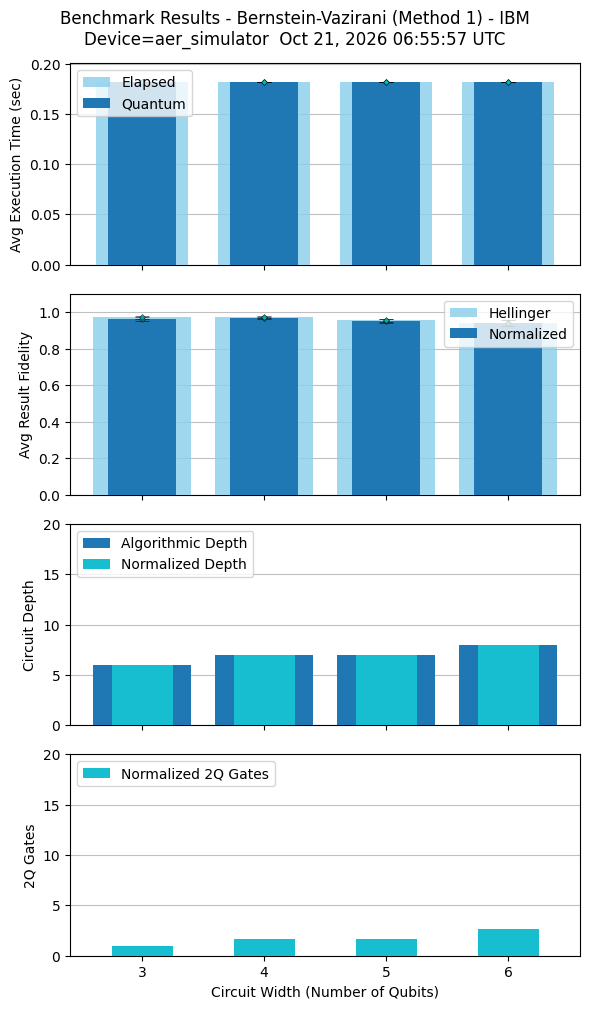

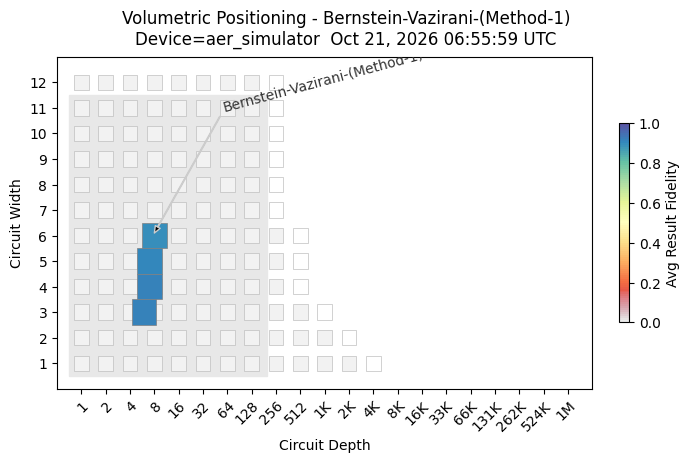

In [9]:
# Set information for plot titles.
benchmark_name = "Bernstein-Vazirani"
provider_name = "IBM"
device_name = "aer_simulator"

# Set plot titles.
benchmark_title = f"{benchmark_name} (Method 1)"
subtitle = f"Benchmark Results - {benchmark_title} - {provider_name}"
metrics.circuit_metrics["subtitle"] = f"device = {device_name}"

# Determine which metrics to plot.
filters = ["execute", "fidelity", "hf_fidelity", "depth", "2q", "vbplot"]

# Plot the metrics.
metrics.plot_metrics(subtitle, filters=filters)

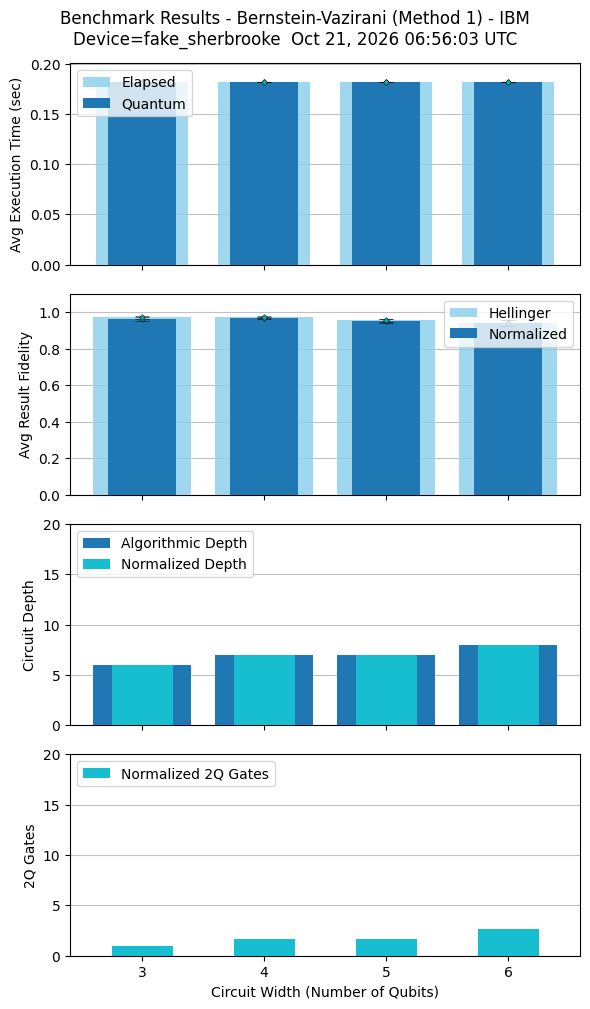

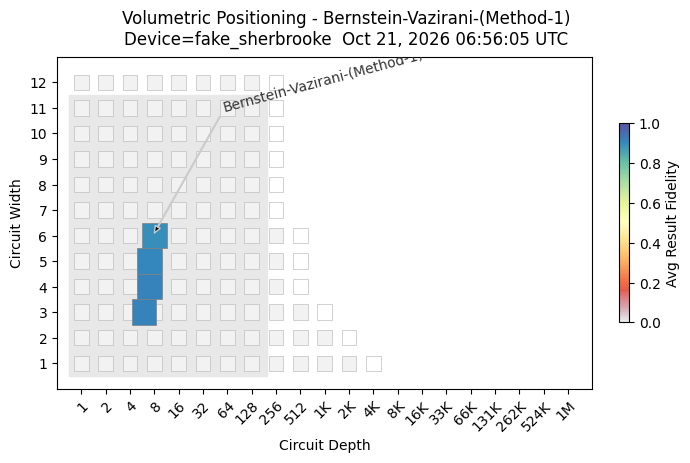

In [10]:
# Set information for plot titles.
benchmark_name = "Bernstein-Vazirani"
provider_name = "IBM"
device_name = "fake_sherbrooke"

# Set plot titles.
benchmark_title = f"{benchmark_name} (Method 1)"
subtitle = f"Benchmark Results - {benchmark_title} - {provider_name}"
metrics.circuit_metrics["subtitle"] = f"device = {device_name}"

# Determine which metrics to plot.
filters = ["execute", "fidelity", "hf_fidelity", "depth", "2q", "vbplot"]

# Plot the metrics.
metrics.plot_metrics(subtitle, filters=filters)